In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

df = pd.read_csv("weather_dataset.csv")

In [54]:
print('Shape: ', df.shape)

Shape:  (43824, 21)


In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   time                             43824 non-null  object 
 1   temperature_2m (°C)              43824 non-null  float64
 2   relative_humidity_2m (%)         43824 non-null  int64  
 3   dew_point_2m (°C)                43824 non-null  float64
 4   apparent_temperature (°C)        43824 non-null  float64
 5   precipitation (mm)               43824 non-null  float64
 6   pressure_msl (hPa)               43824 non-null  float64
 7   surface_pressure (hPa)           43824 non-null  float64
 8   cloud_cover (%)                  43824 non-null  int64  
 9   cloud_cover_low (%)              43824 non-null  int64  
 10  cloud_cover_mid (%)              43824 non-null  int64  
 11  cloud_cover_high (%)             43824 non-null  int64  
 12  wind_speed_10m (km

In [58]:
df.describe()

,temperature_2m (°C),relative_humidity_2m (%),dew_point_2m (°C),apparent_temperature (°C),precipitation (mm),pressure_msl (hPa),surface_pressure (hPa),cloud_cover (%),cloud_cover_low (%),cloud_cover_mid (%),cloud_cover_high (%),wind_speed_10m (km/h),wind_speed_100m (km/h),wind_direction_10m (°),wind_direction_100m (°),wind_gusts_10m (km/h),soil_temperature_0_to_7cm (°C),soil_temperature_7_to_28cm (°C),soil_moisture_0_to_7cm (m³/m³),soil_moisture_7_to_28cm (m³/m³)
count,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000
mean,24.014043,78.758123,19.808835,27.057010,0.254682,1011.186781,1009.672077,73.422234,38.598941,25.896929,44.601976,9.060417,15.050345,124.527725,124.282608,18.959618,24.992150,24.919079,0.323704,0.325496
std,5.559314,14.852765,6.357908,8.299949,1.075437,7.436929,7.408559,37.252699,42.853039,35.459694,44.207675,4.575703,7.399587,92.411475,87.895689,8.308161,5.020164,4.314813,0.078584,0.068425
min,6.300000,22.000000,-8.900000,2.300000,0.000000,983.500000,982.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.700000,9.200000,11.600000,0.099000,0.138000
25%,20.200000,69.000000,15.600000,21.000000,0.000000,1005.100000,1003.600000,43.000000,1.000000,1.000000,0.000000,5.600000,9.400000,42.000000,45.000000,13.000000,21.200000,21.200000,0.271000,0.275000
50%,24.900000,81.000000,22.100000,28.700000,0.000000,1010.800000,1009.300000,99.000000,14.000000,8.000000,29.000000,8.400000,14.500000,122.000000,128.000000,18.000000,25.800000,25.900000,0.339000,0.334000
75%,27.900000,92.000000,25.000000,33.400000,0.100000,1016.900000,1015.400000,100.000000,100.000000,35.000000,98.000000,11.900000,20.000000,159.000000,159.000000,24.100000,28.700000,28.600000,0.388000,0.383000
max,39.000000,100.000000,28.800000,46.500000,35.600000,1034.500000,1032.900000,100.000000,100.000000,100.000000,100.000000,58.300000,89.600000,360.000000,360.000000,106.200000,37.000000,32.800000,0.438000,0.431000


In [59]:
# Check null value
df.isnull().sum()

time                               0
temperature_2m (°C)                0
relative_humidity_2m (%)           0
dew_point_2m (°C)                  0
apparent_temperature (°C)          0
precipitation (mm)                 0
pressure_msl (hPa)                 0
surface_pressure (hPa)             0
cloud_cover (%)                    0
cloud_cover_low (%)                0
cloud_cover_mid (%)                0
cloud_cover_high (%)               0
wind_speed_10m (km/h)              0
wind_speed_100m (km/h)             0
wind_direction_10m (°)             0
wind_direction_100m (°)            0
wind_gusts_10m (km/h)              0
soil_temperature_0_to_7cm (°C)     0
soil_temperature_7_to_28cm (°C)    0
soil_moisture_0_to_7cm (m³/m³)     0
soil_moisture_7_to_28cm (m³/m³)    0
dtype: int64

In [ ]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

n_cols = 2
n_rows = math.ceil(len(num_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(
        df[col].dropna(),
        bins=30,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"{col}")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

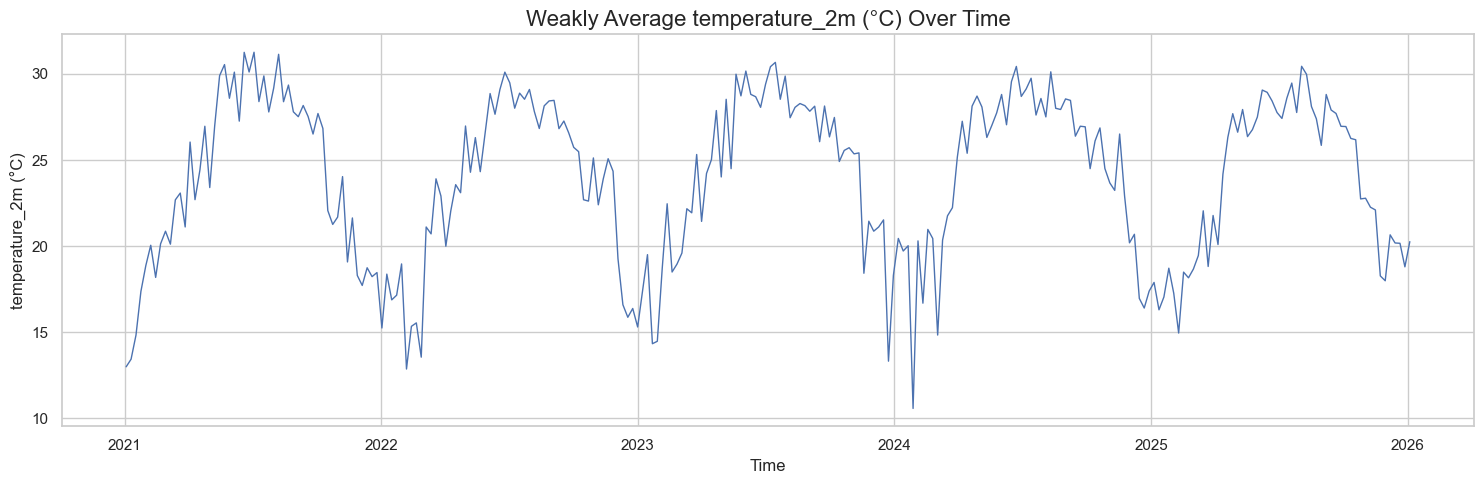

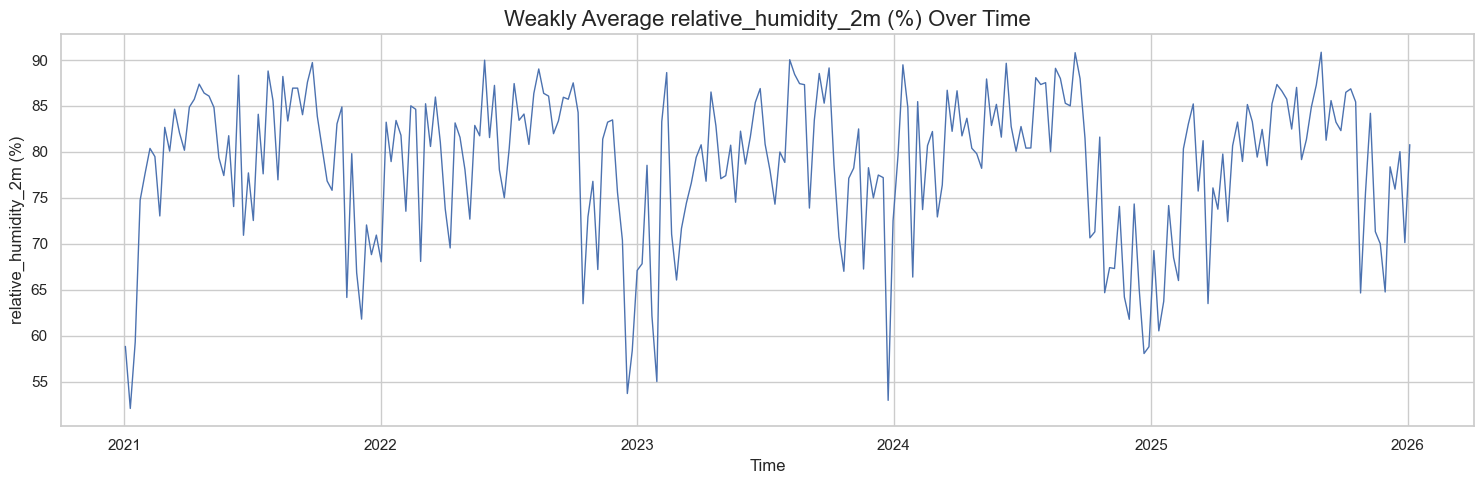

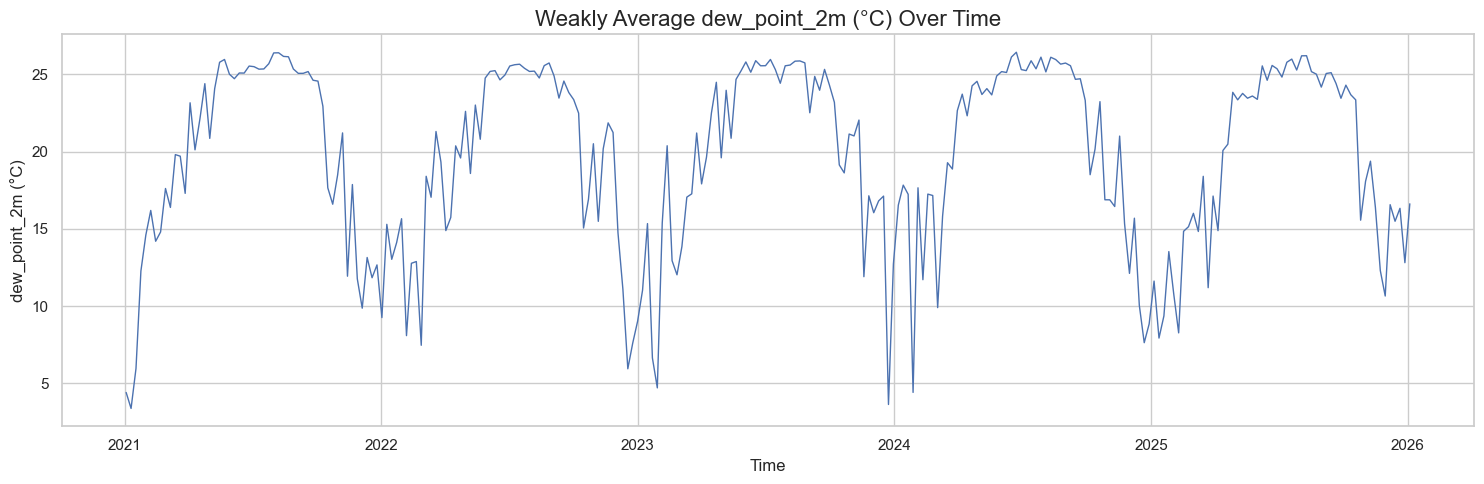

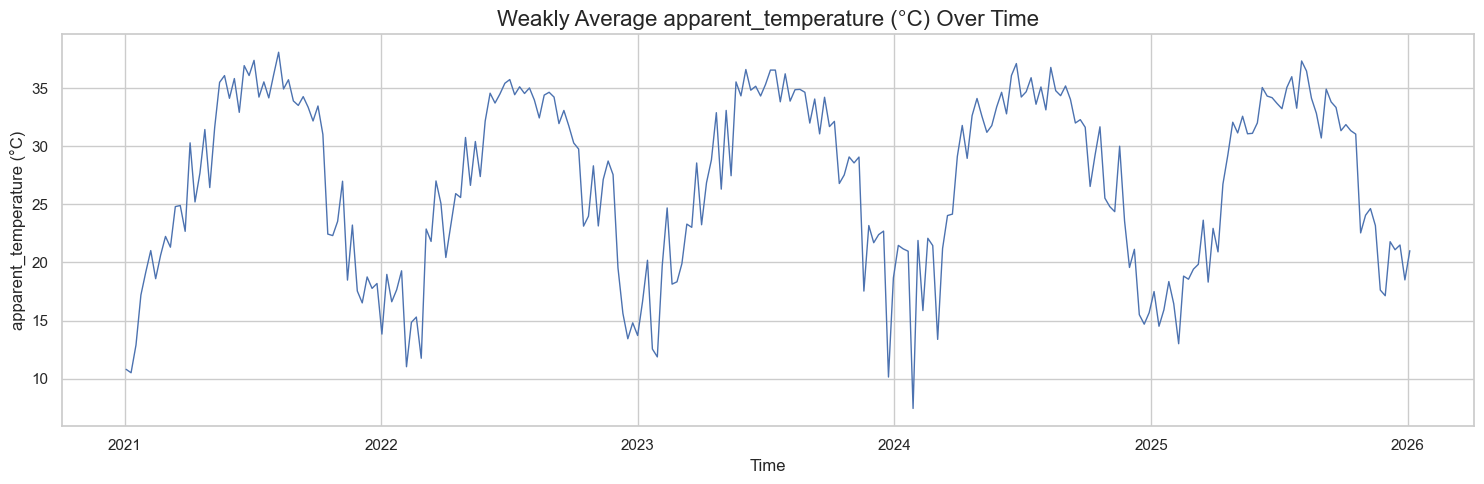

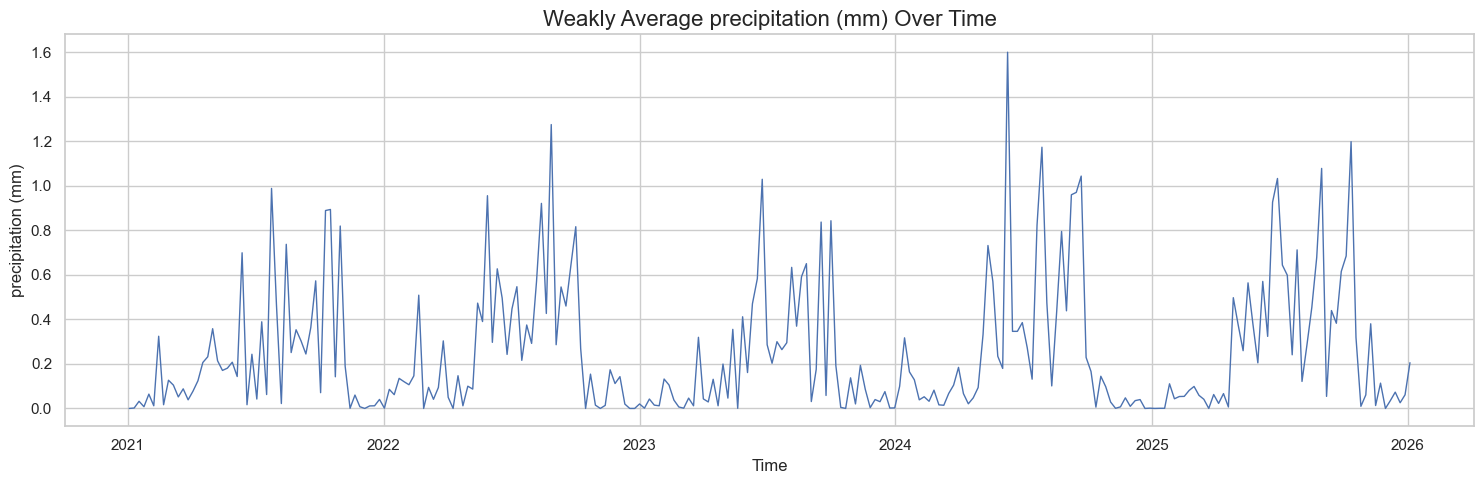

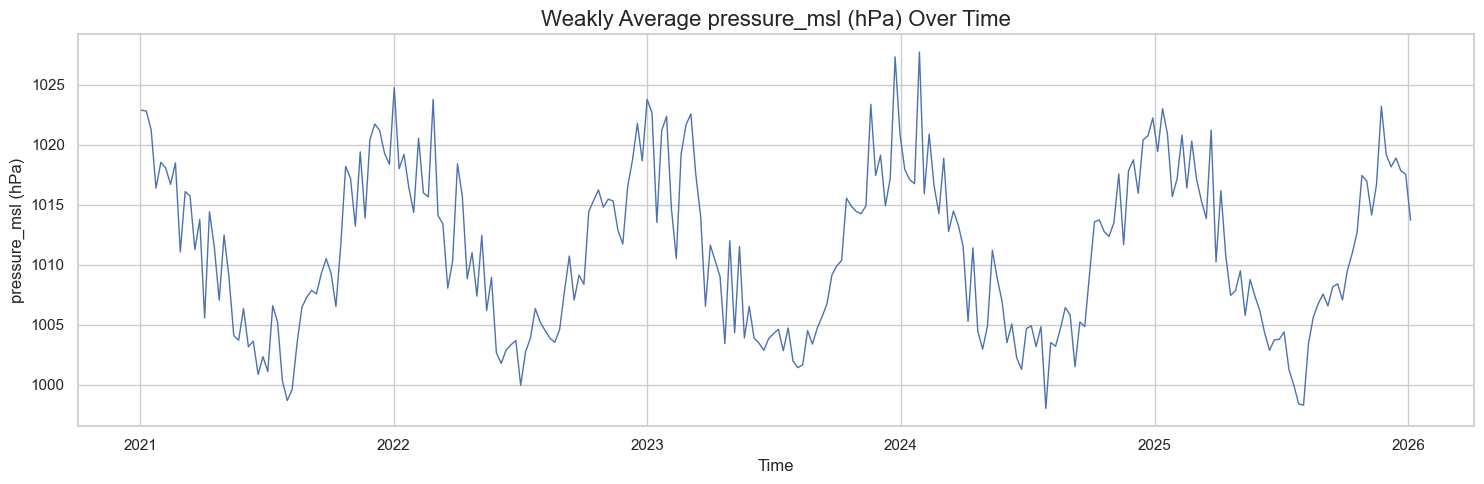

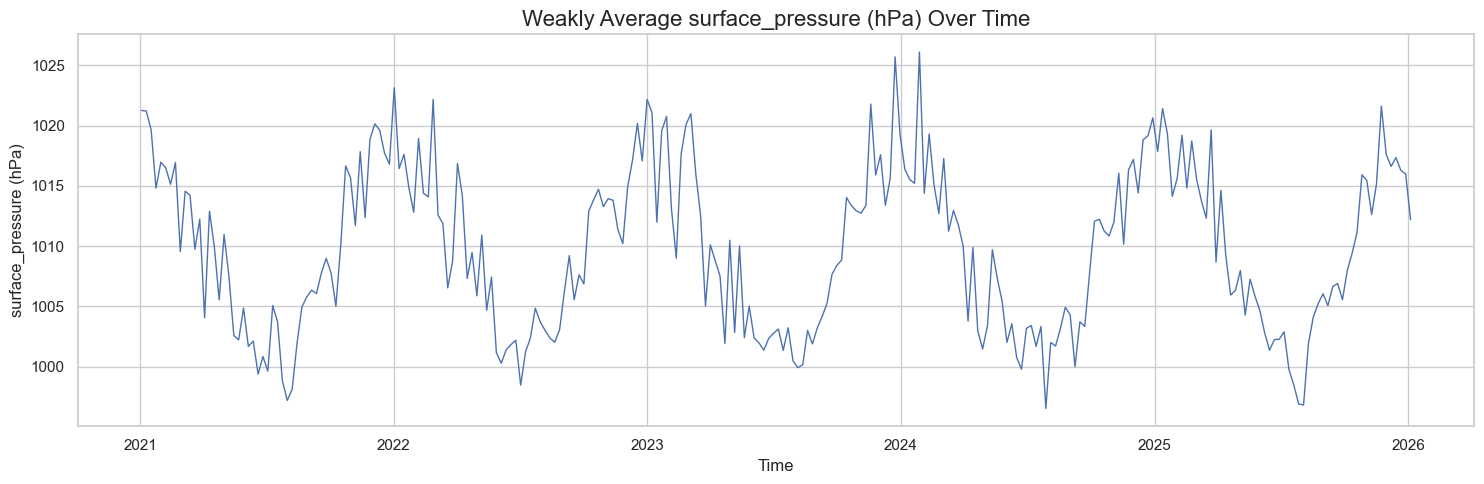

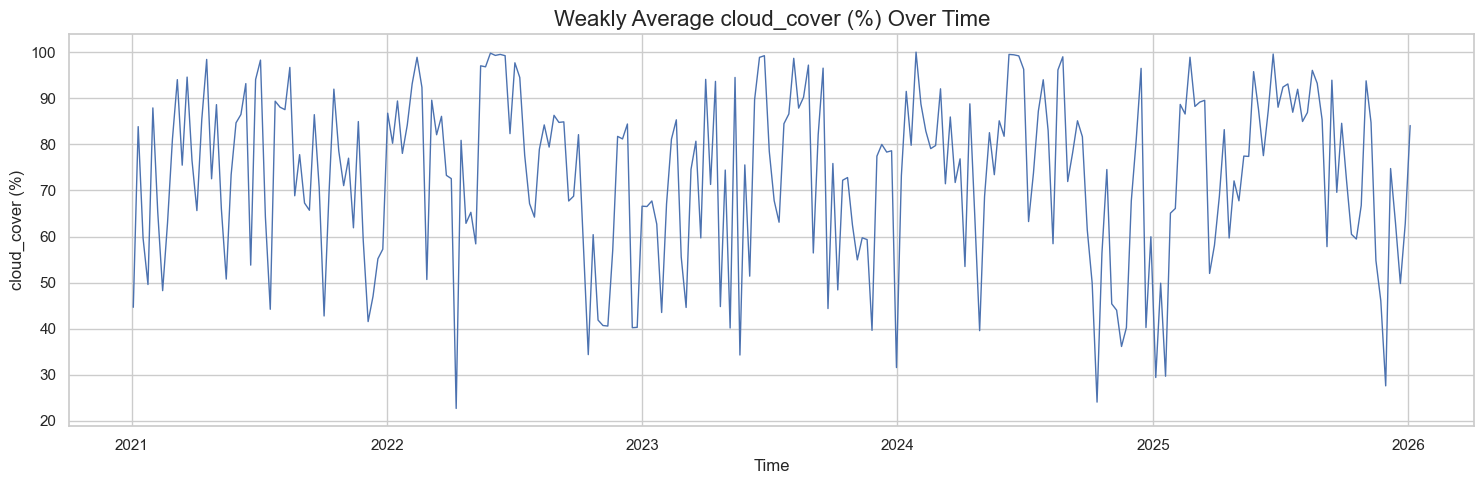

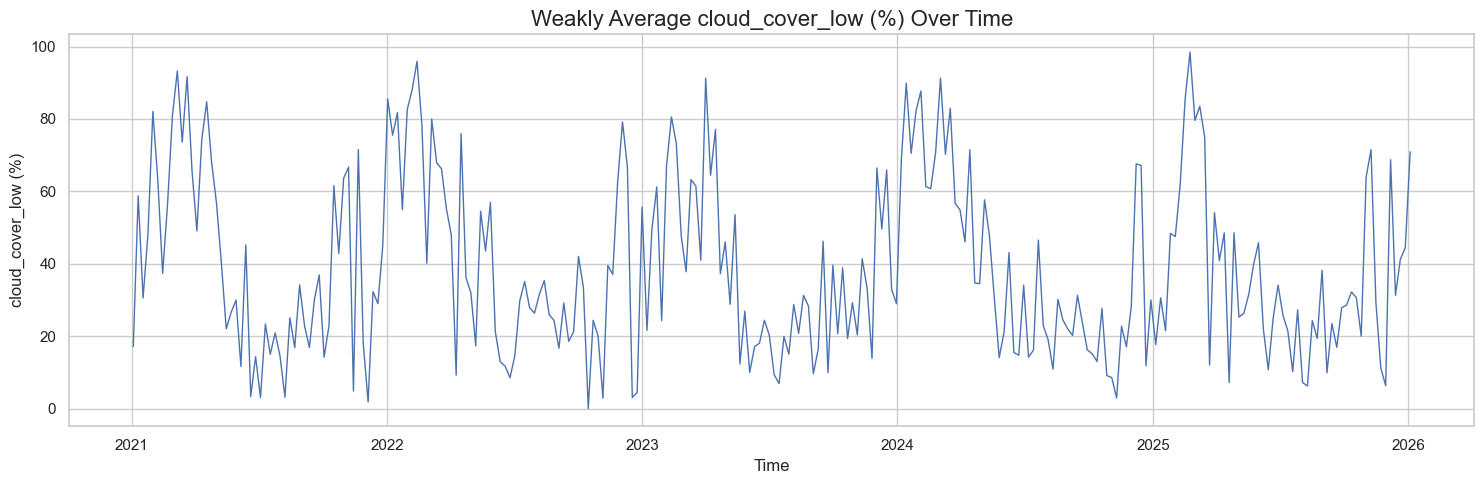

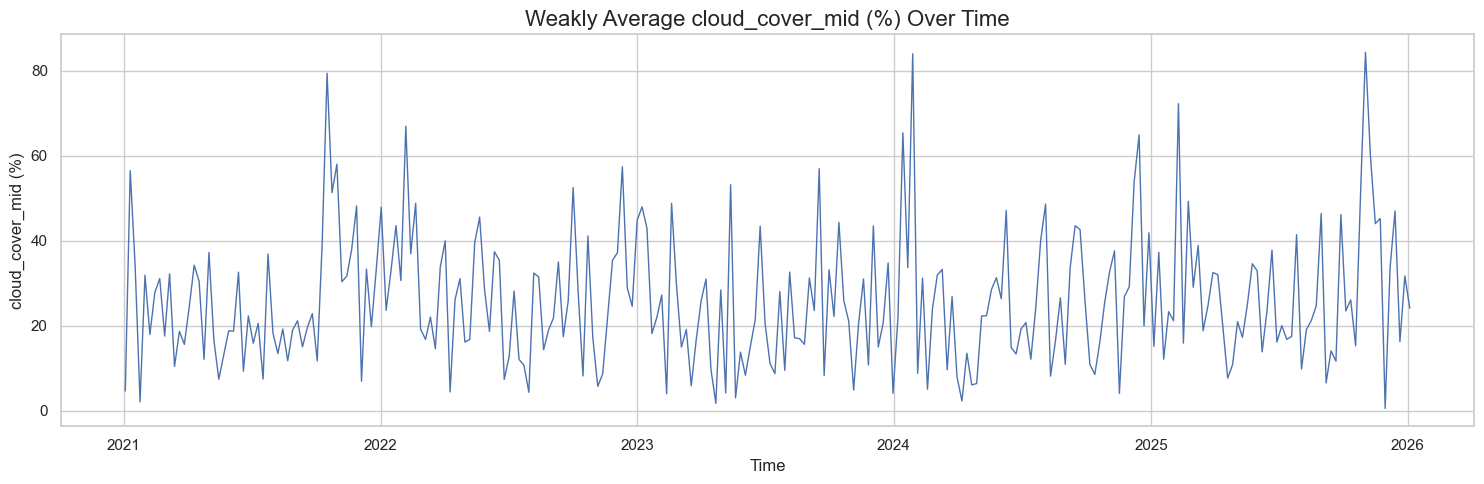

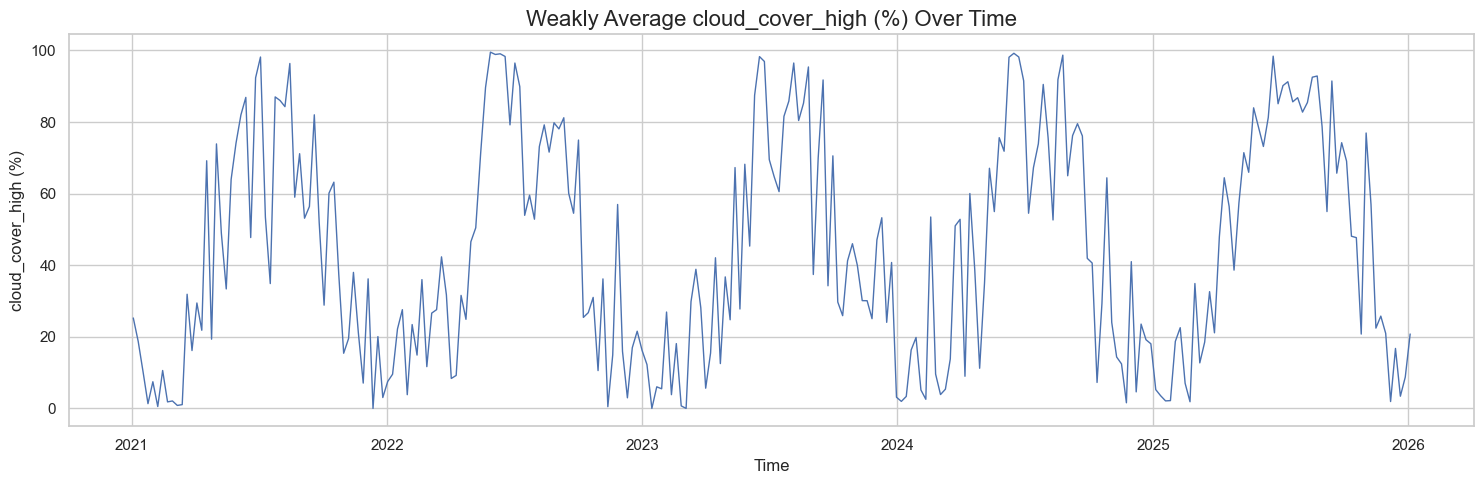

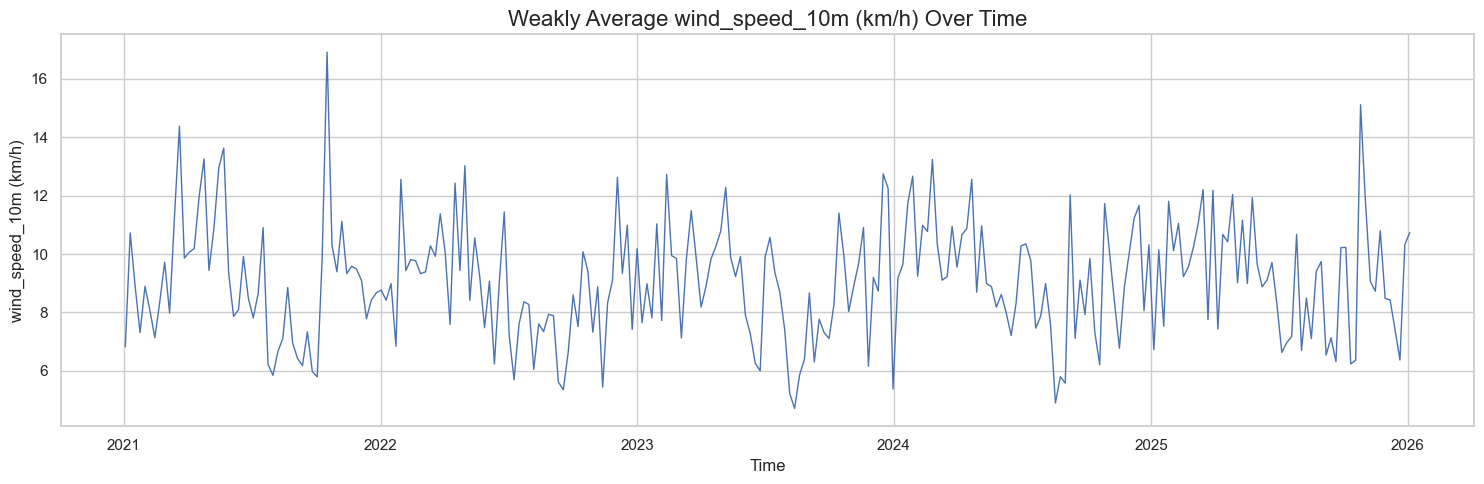

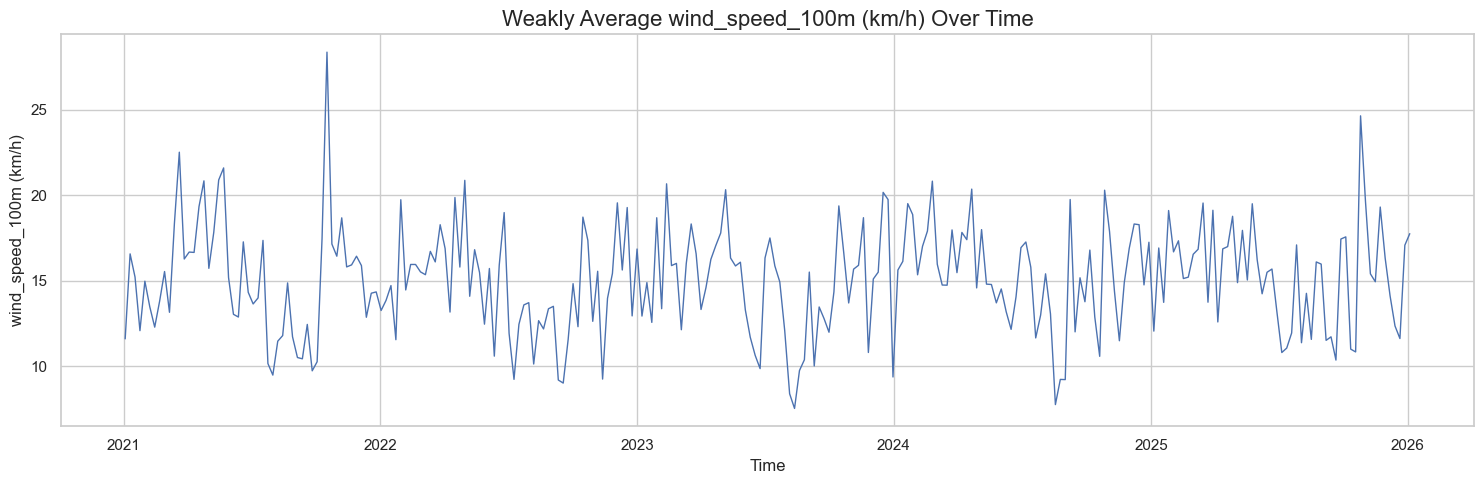

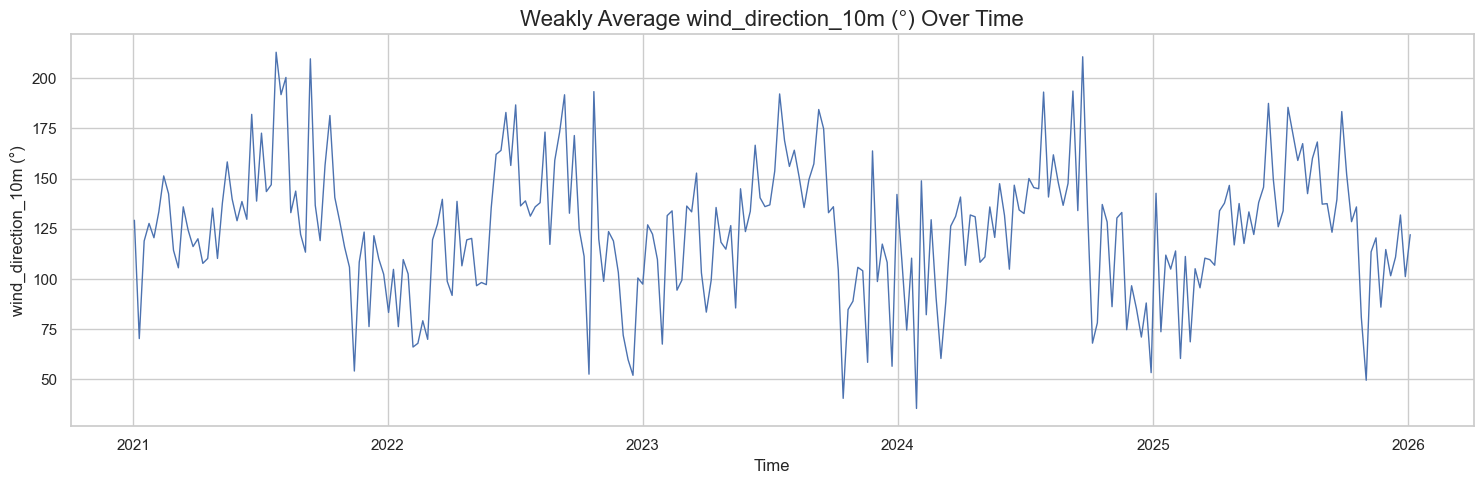

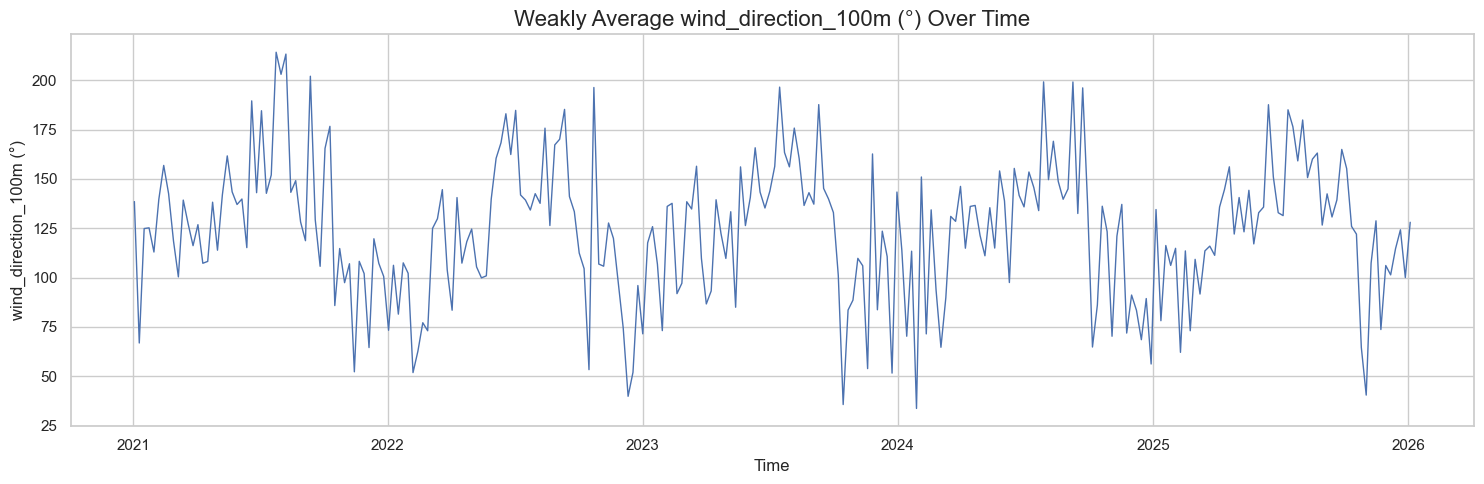

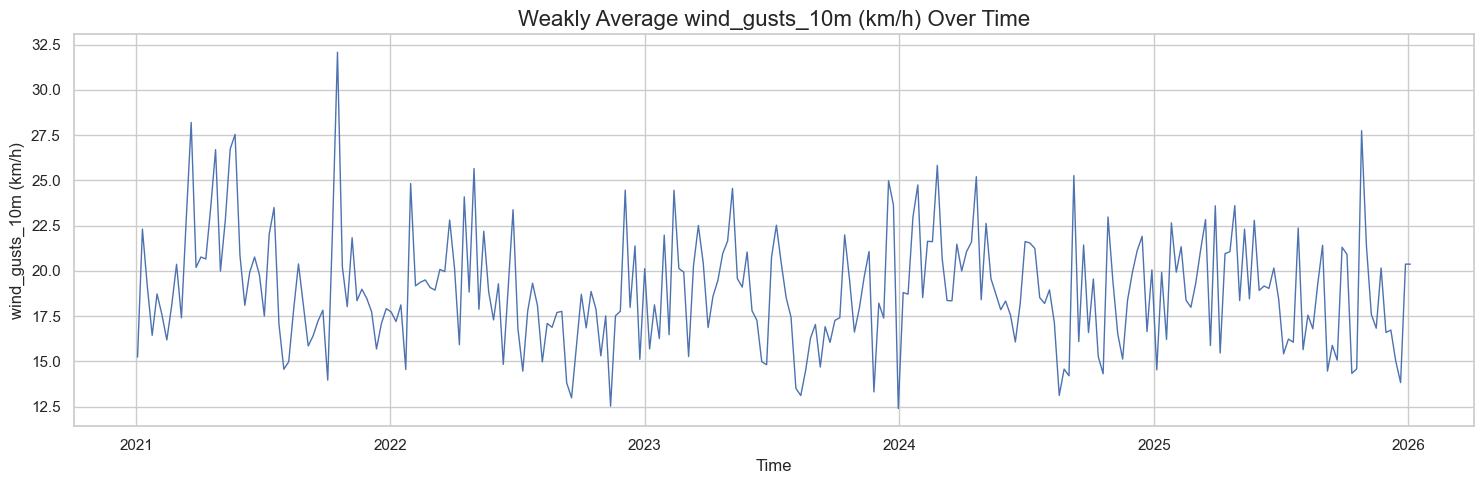

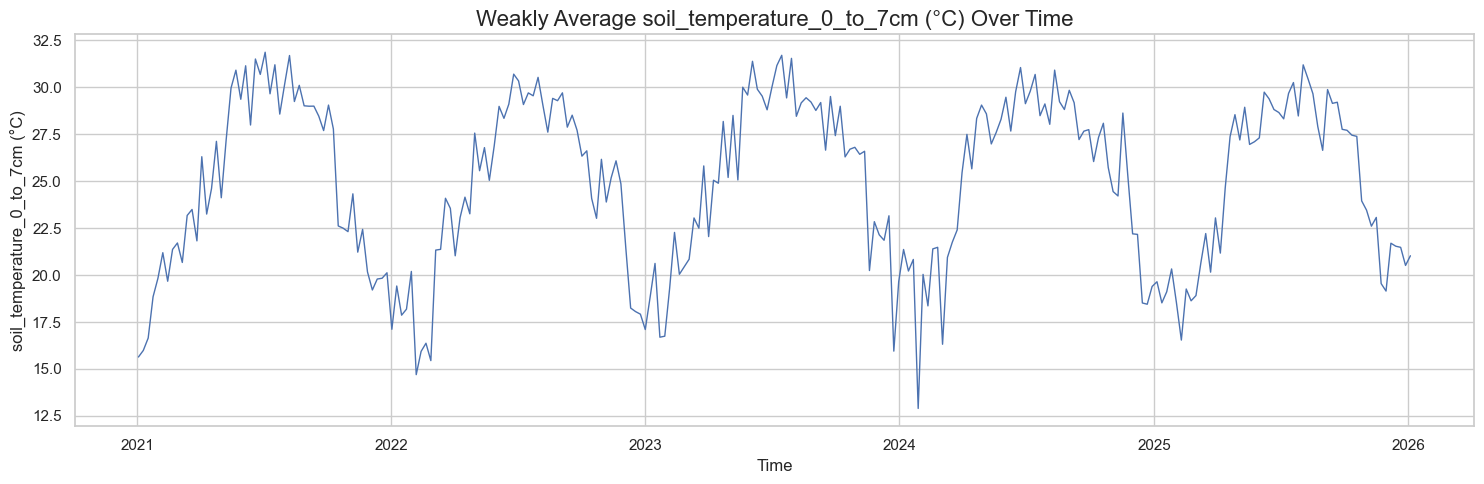

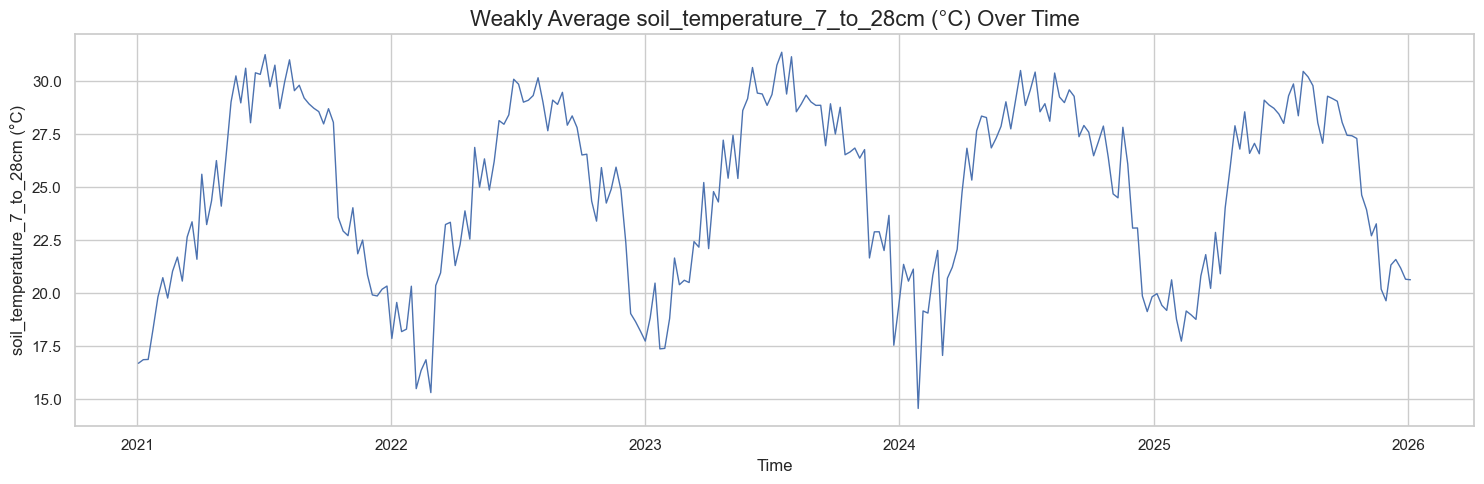

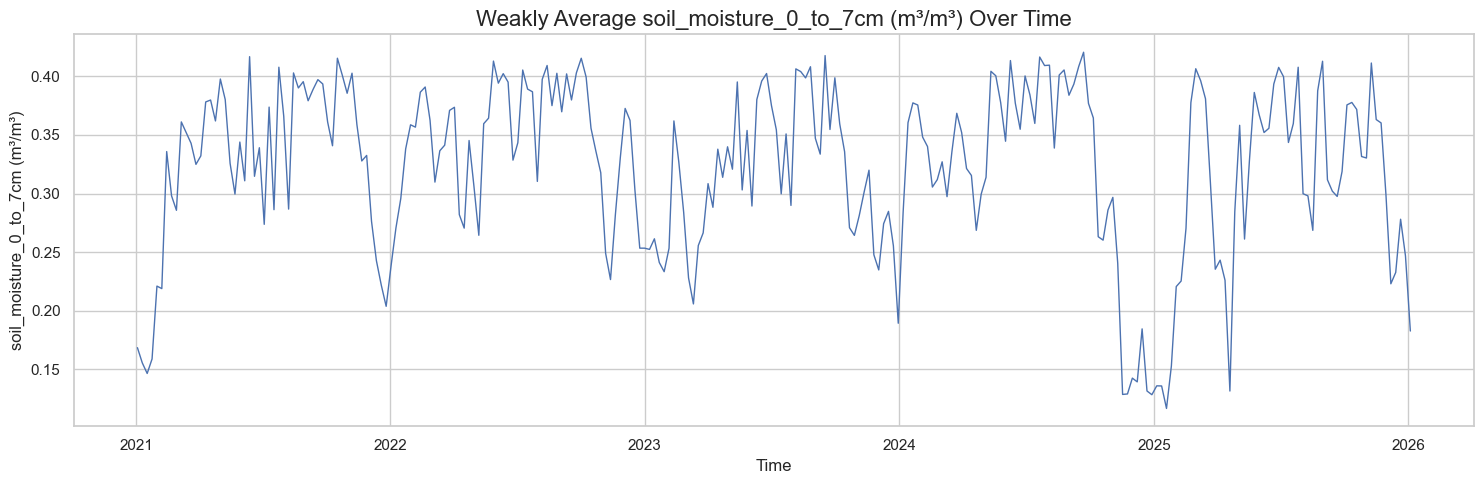

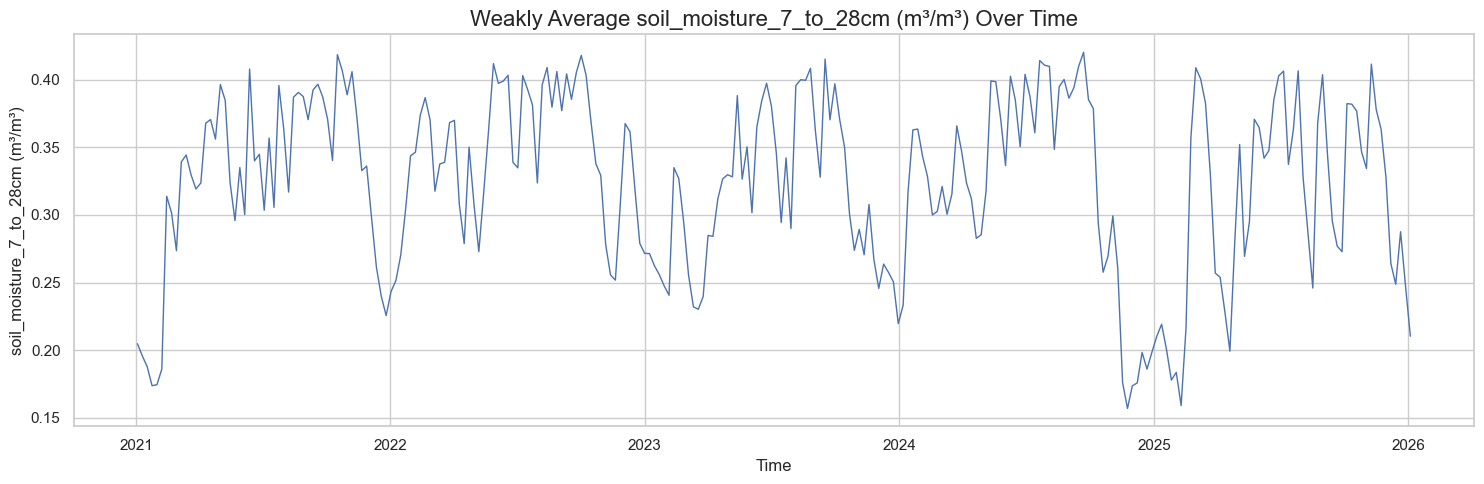

In [74]:
# Convert time column
df['time'] = pd.to_datetime(df['time'])

# Select numerical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Plot all features with DAILY average
for col in num_cols:

    # Resample by day
    daily_data = (
        df
        .set_index('time')[col]
        .resample('W')
        .mean()
    )

    # Plot
    plt.figure(figsize=(15, 5))

    sns.lineplot(
        x=daily_data.index,
        y=daily_data.values,
        linewidth=1
    )

    plt.title(f'Weakly Average {col} Over Time', fontsize=16)

    plt.xlabel('Time')
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

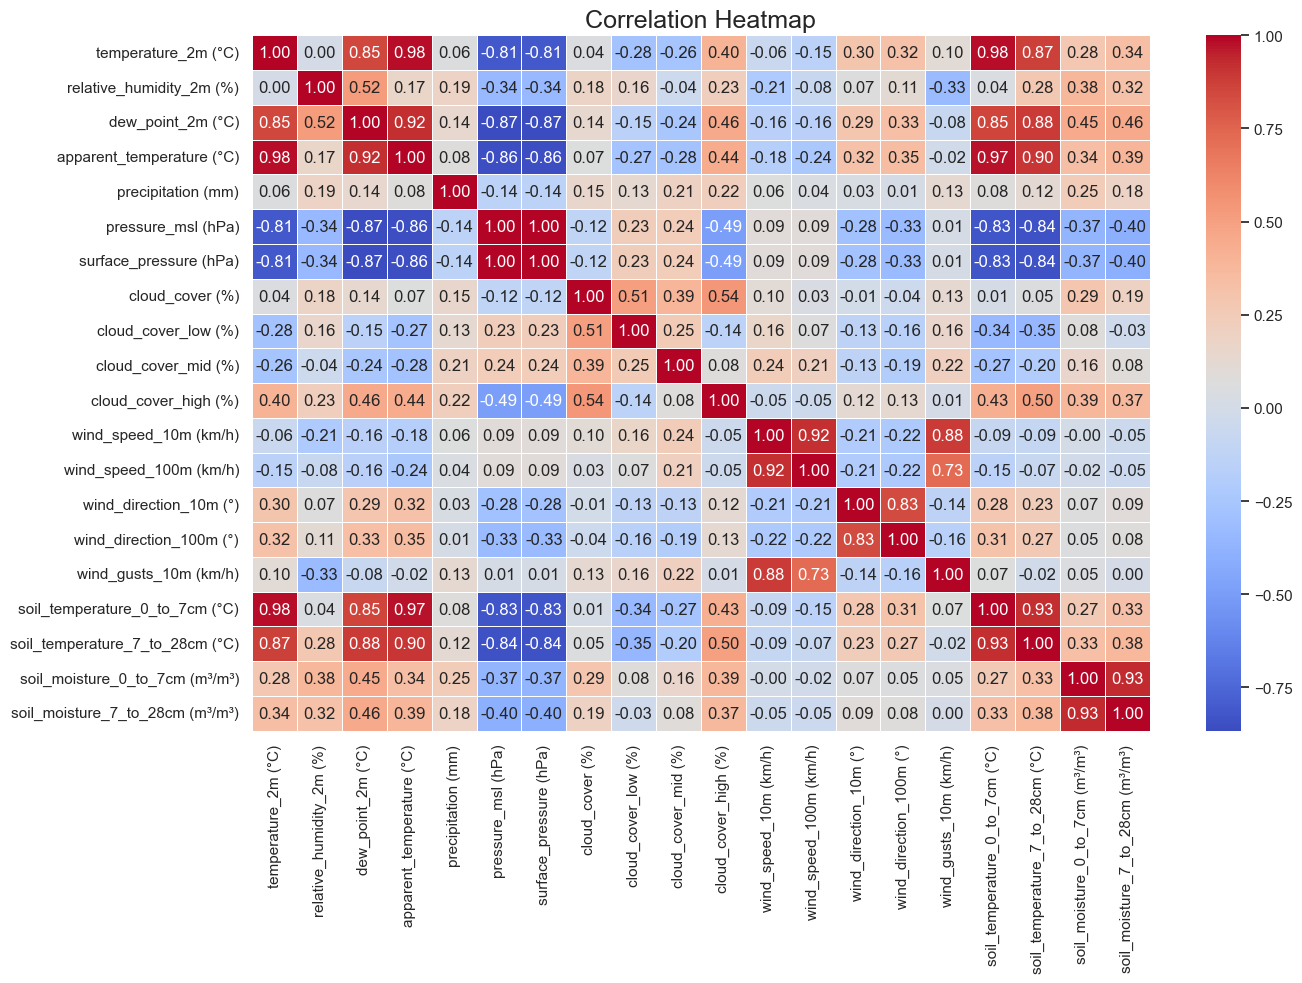

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns only
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Compute correlation matrix
corr_matrix = df[num_cols].corr()

# Plot heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,        # show correlation values
    fmt=".2f",         # 2 decimal places
    cmap='coolwarm',  # color map
    linewidths=0.5
)

plt.title('Correlation Heatmap', fontsize=18)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from windrose import WindroseAxes
HAS_WINDROSE = True

# Thiết lập chung cho biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (15, 6)


def plot_wind_rose(df):
    """Bước 5: Vẽ biểu đồ Hoa hồng gió (Wind Rose)"""
    print("\n" + "="*50 + "\n5. BIỂU ĐỒ HOA HỒNG GIÓ\n" + "="*50)
    if not HAS_WINDROSE:
        print("Bỏ qua phần vẽ Hoa hồng gió do thiếu thư viện.")
        return
        
    ax = WindroseAxes.from_ax()
    # bins giúp chia dải tốc độ gió
    ax.bar(df['wind_direction_10m (°)'], df['wind_speed_10m (km/h)'], 
           normed=True, opening=0.8, edgecolor='white', bins=np.arange(0, 30, 5))
    ax.set_title("Biểu đồ Hoa hồng gió (Hướng & Tốc độ)", fontsize=16)
    ax.set_legend()
    plt.show()


# ==========================================
# CHẠY TỔNG HỢP (MAIN FUNCTION)
# ==========================================
FILE_NAME = "weather_dataset.csv"

df = pd.read_csv(FILE_NAME)  
df['time'] = pd.to_datetime(df['time'])     
plot_wind_rose(df)
        


 VẼ BOXPLOT TÌM GIÁ TRỊ NGOẠI LỆ CHO TẤT CẢ CỘT SỐ
Phát hiện 18 cột dữ liệu số để vẽ biểu đồ.


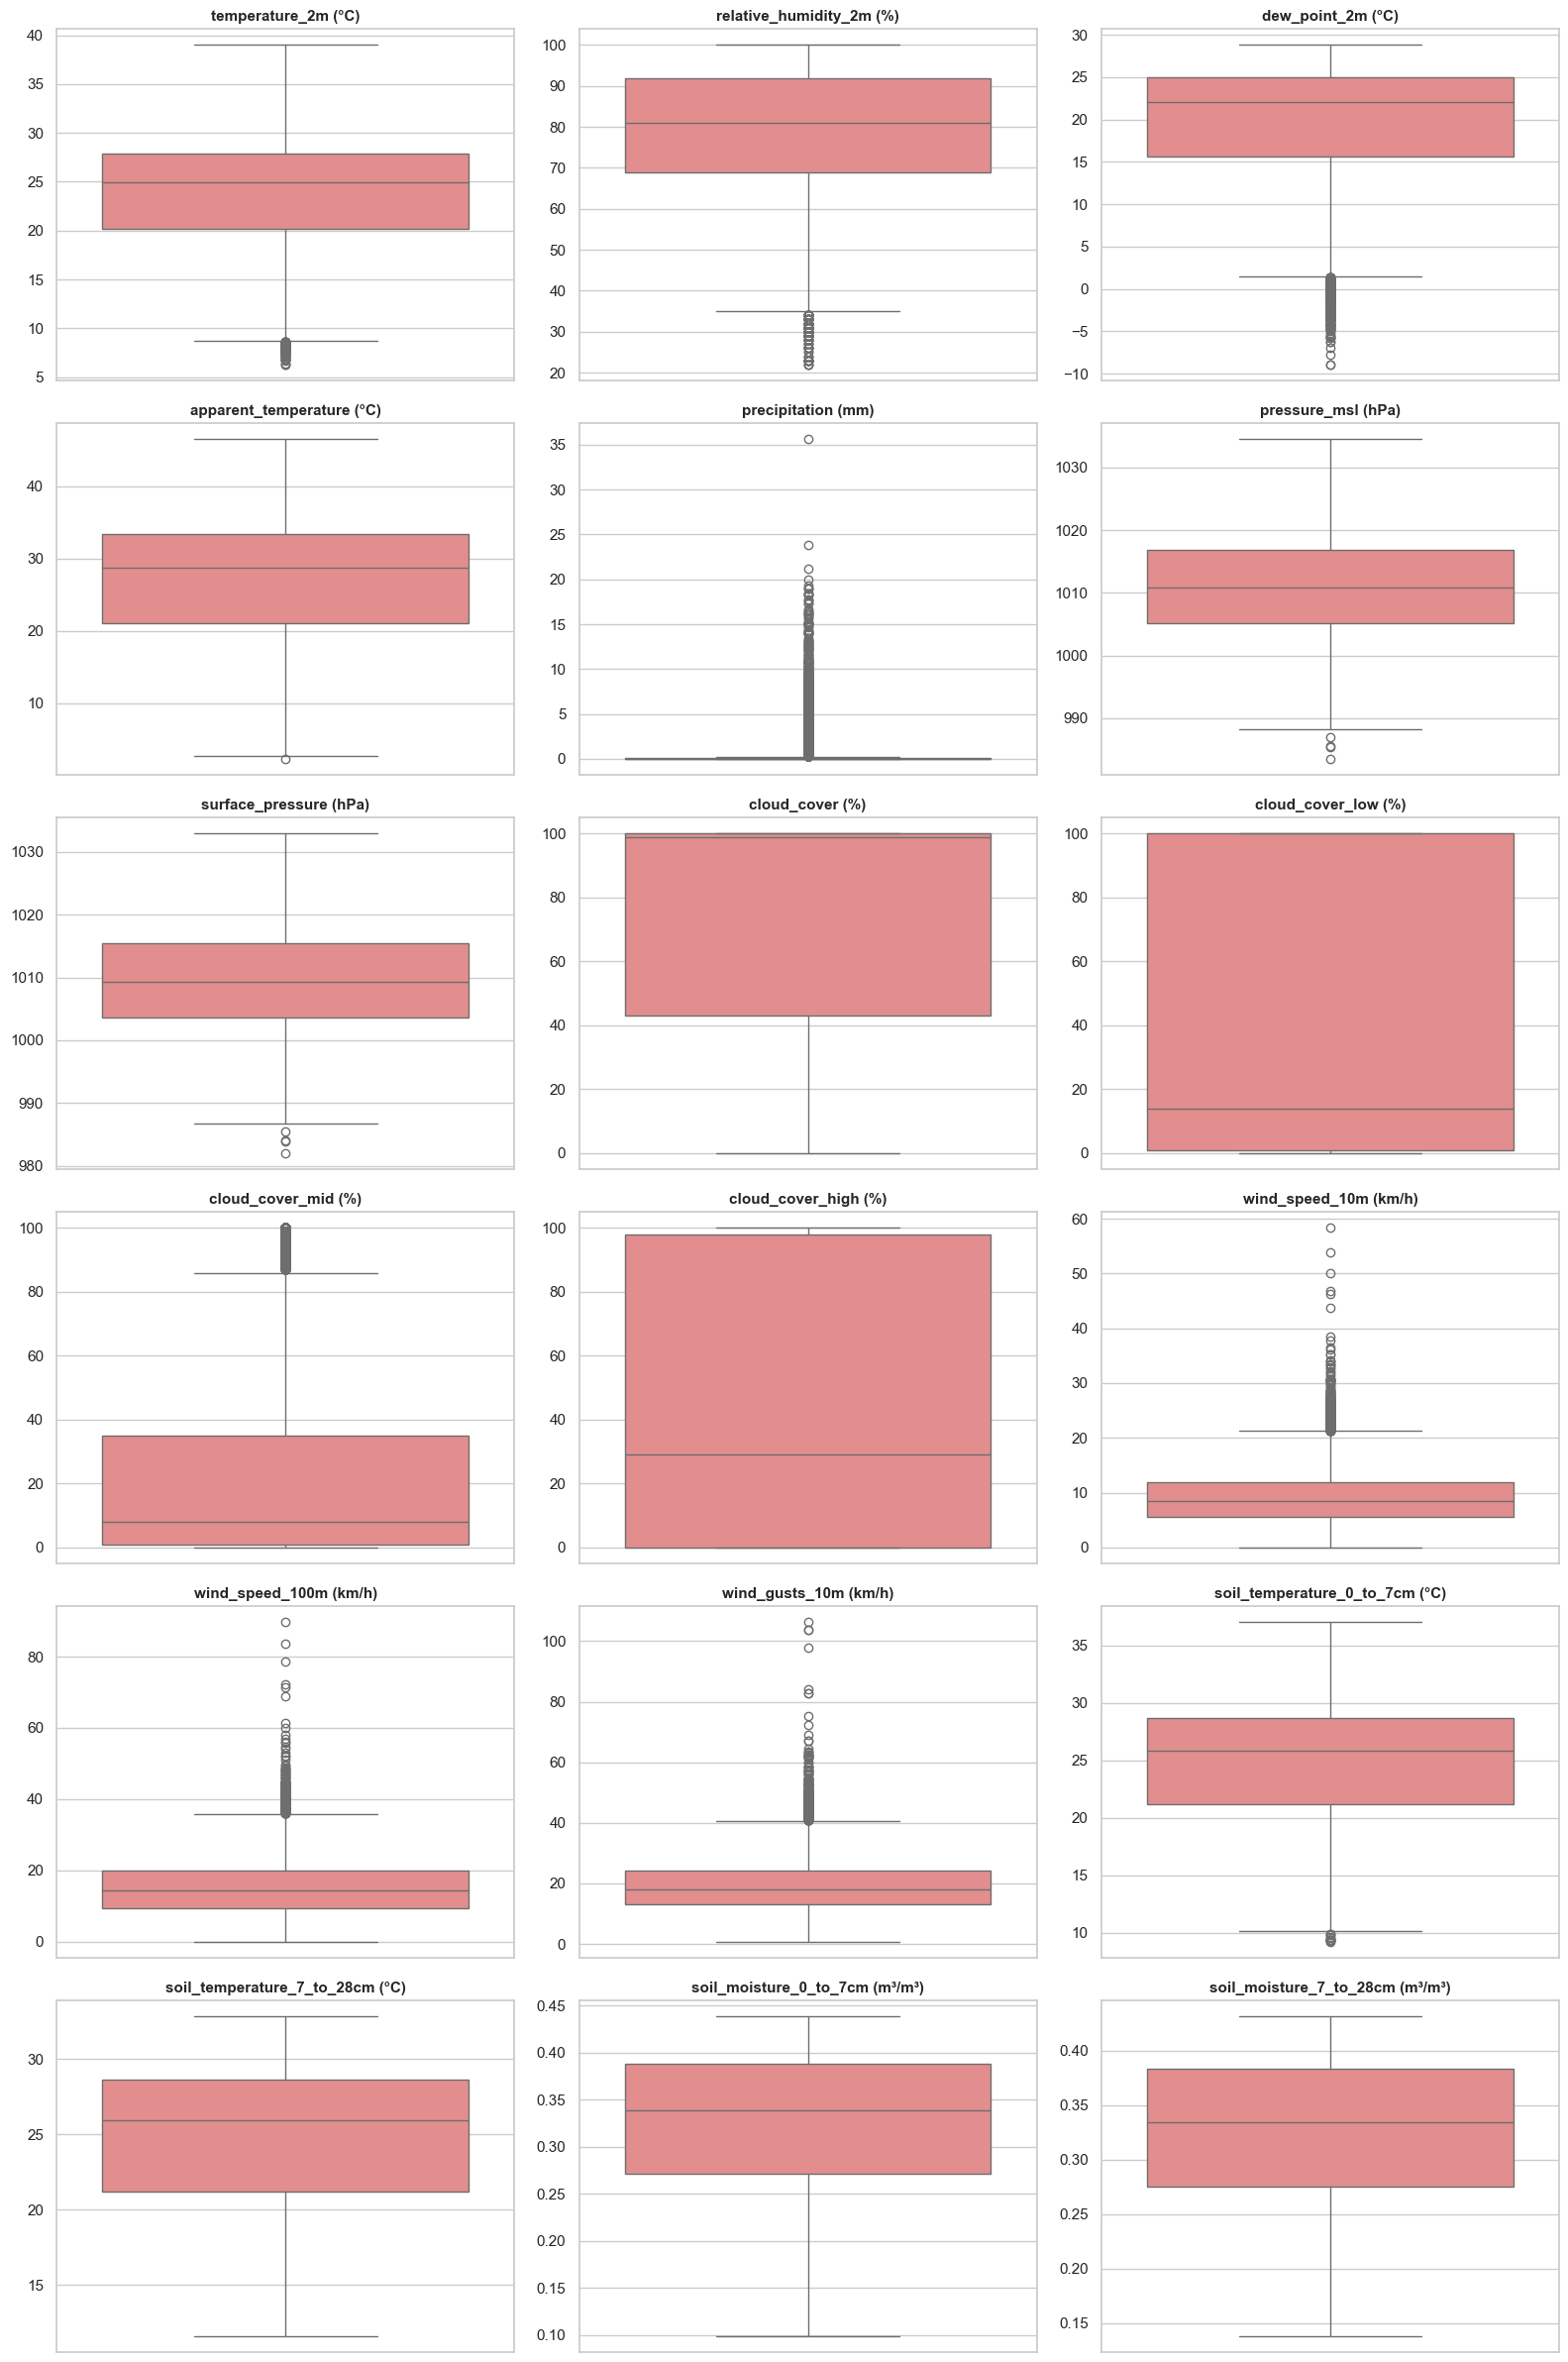

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Thiết lập giao diện
sns.set_theme(style="whitegrid")

def plot_all_boxplots(df):
    """
    Hàm tự động quét tất cả các cột số trong DataFrame và vẽ Boxplot để tìm Outliers
    """
    print("\n" + "="*60)
    print(" VẼ BOXPLOT TÌM GIÁ TRỊ NGOẠI LỆ CHO TẤT CẢ CỘT SỐ")
    print("="*60)
    
    # 1. Tự động lọc ra các cột có kiểu dữ liệu là số (int, float)
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    
    # (Tùy chọn) Bạn có thể loại bỏ các cột không muốn vẽ (ví dụ: hướng gió tính bằng độ)
    cols_to_exclude = ['wind_direction_10m (°)', 'wind_direction_100m (°)']
    num_cols = [col for col in num_cols if col not in cols_to_exclude]
    
    n_cols = len(num_cols)
    print(f"Phát hiện {n_cols} cột dữ liệu số để vẽ biểu đồ.")
    
    if n_cols == 0:
        print("Không có cột dữ liệu số nào trong DataFrame!")
        return

    # 2. Tính toán lưới hiển thị (3 biểu đồ trên 1 hàng)
    cols_per_row = 3
    rows = math.ceil(n_cols / cols_per_row)
    
    # Tạo khung vẽ tổng (chiều cao sẽ tự động tăng theo số hàng)
    fig, axes = plt.subplots(rows, cols_per_row, figsize=(16, rows * 4))
    
    # Làm phẳng mảng lưới để dễ dàng dùng vòng lặp for
    axes = axes.flatten() 
    
    # 3. Vòng lặp để vẽ Boxplot cho từng cột
    for i, col in enumerate(num_cols):
        sns.boxplot(data=df, y=col, ax=axes[i], color='lightcoral')
        axes[i].set_title(f'{col}', fontsize=11, fontweight='bold')
        axes[i].set_ylabel('') # Ẩn nhãn trục y cho đỡ rối mắt
        
    # 4. Xóa/Ẩn các khung vẽ trống (nếu số lượng cột không chia hết cho 3)
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
        
    plt.tight_layout()
    plt.show()

# ==========================================
# CHẠY THỬ NGHIỆM
# ==========================================
if __name__ == "__main__":
        
        # Gọi hàm
    plot_all_boxplots(df)



 PHÂN TÍCH TÍNH MÙA VỤ CHO BIẾN: 'temperature_2m (°C)'
Đang resample dữ liệu từ theo giờ (Hourly) sang theo ngày (Daily)...
Đang phân tách các thành phần Trend, Seasonality, Residual...


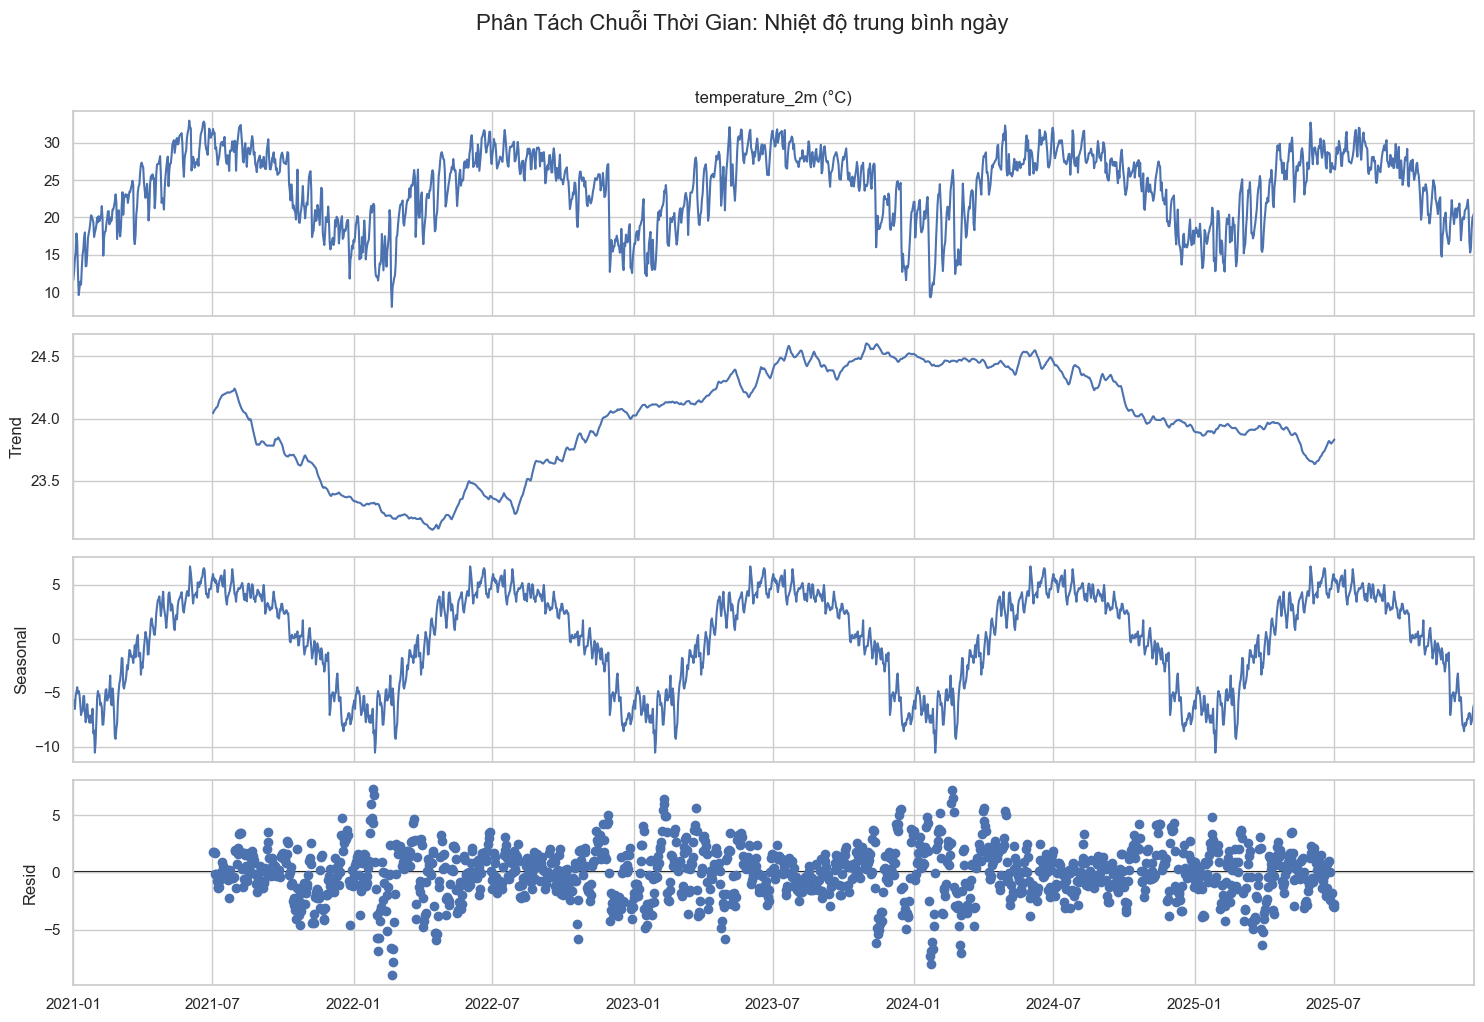


Đang vẽ biểu đồ Autocorrelation (ACF)...


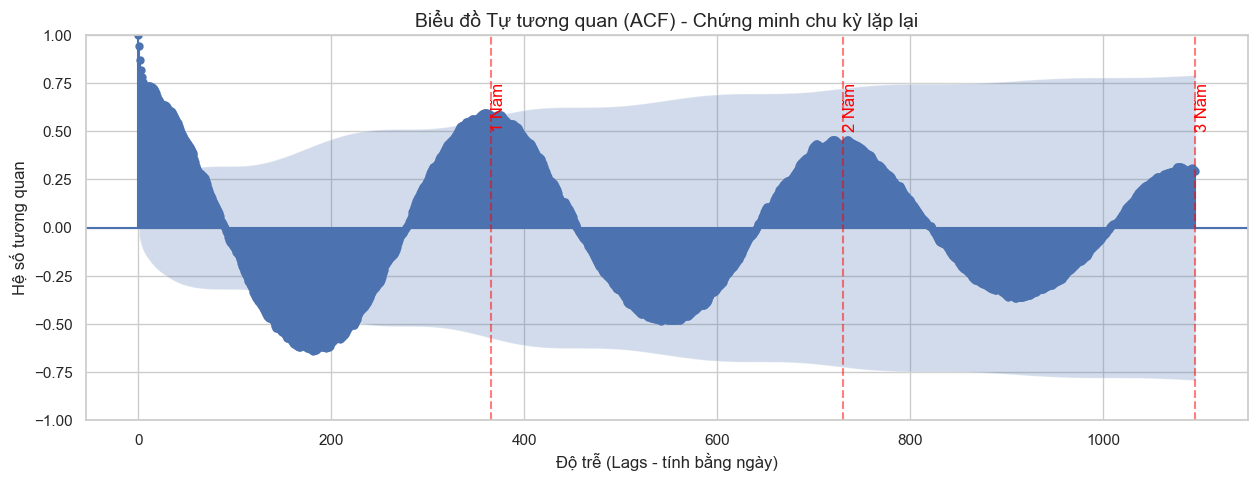

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf

# Thiết lập giao diện biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (15, 8)

def analyze_seasonality(df, date_col='time', target_col='temperature_2m (°C)'):
    """
    Hàm phân tích tính mùa vụ (Seasonality) và Xu hướng (Trend)
    """
    print("\n" + "="*60)
    print(f" PHÂN TÍCH TÍNH MÙA VỤ CHO BIẾN: '{target_col}'")
    print("="*60)
    
    # 1. Tiền xử lý: Đảm bảo cột thời gian là index
    df_temp = df.copy()
    if df_temp[date_col].dtype != 'datetime64[ns]':
        df_temp[date_col] = pd.to_datetime(df_temp[date_col])
    
    df_temp = df_temp.set_index(date_col)
    
    # 2. Gom nhóm dữ liệu theo Ngày (Daily Resampling)
    # Dữ liệu gốc là theo giờ (hourly) -> Rất nhiễu. Ta tính trung bình mỗi ngày.
    print("Đang resample dữ liệu từ theo giờ (Hourly) sang theo ngày (Daily)...")
    daily_data = df_temp[target_col].resample('D').mean().dropna()
    
    # Kiểm tra xem dữ liệu có đủ dài để phân tích chu kỳ năm (365 ngày) không
    if len(daily_data) < 365 * 2:
        print("Lỗi: Dữ liệu quá ngắn. Cần ít nhất 2 năm dữ liệu để thấy rõ chu kỳ mùa vụ hàng năm.")
        return
        
    # 3. Phân tách chuỗi thời gian (Time-Series Decomposition)
    print("Đang phân tách các thành phần Trend, Seasonality, Residual...")
    # Sử dụng model 'additive' (cộng gộp) vì nhiệt độ có thể có giá trị âm/0
    # period = 365 tức là chu kỳ lặp lại sau mỗi 365 ngày (1 năm)
    decomposition = seasonal_decompose(daily_data, model='additive', period=365)
    
    # Vẽ biểu đồ Decomposition
    fig_decomp = decomposition.plot()
    fig_decomp.set_size_inches(15, 10)
    fig_decomp.suptitle(f'Phân Tách Chuỗi Thời Gian: Nhiệt độ trung bình ngày', fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()

    # 4. Biểu đồ Tự tương quan (Autocorrelation Function - ACF)
    # Giúp chứng minh bằng thống kê rằng dữ liệu lặp lại sau mỗi độ trễ (lag) nhất định
    print("\nĐang vẽ biểu đồ Autocorrelation (ACF)...")
    plt.figure(figsize=(15, 5))
    # Tính lag cho khoảng 3 năm (365 * 3 = 1095 ngày) để thấy 3 đỉnh chu kỳ
    plot_acf(daily_data, lags=1095, ax=plt.gca(), alpha=0.05) 
    plt.title('Biểu đồ Tự tương quan (ACF) - Chứng minh chu kỳ lặp lại', fontsize=14)
    plt.xlabel('Độ trễ (Lags - tính bằng ngày)')
    plt.ylabel('Hệ số tương quan')
    
    # Thêm các đường gióng tại các mốc 1 năm, 2 năm, 3 năm để dễ nhìn
    for year_lag in [365, 730, 1095]:
        plt.axvline(x=year_lag, color='red', linestyle='--', alpha=0.5)
        plt.text(year_lag, 0.5, f'{year_lag//365} Năm', color='red', rotation=90, va='bottom')
        
    plt.show()


analyze_seasonality(df, date_col='time', target_col='temperature_2m (°C)')


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Thiết lập giao diện biểu đồ
sns.set_theme(style="whitegrid")

def analyze_hourly_cyclic_pattern(df, date_col='time', target_col='temperature_2m (°C)'):
    """
    Hàm phân tích chu kỳ lặp lại theo giờ trong ngày (Hourly Cyclic Pattern)
    """
    print("\n" + "="*60)
    print(f" PHÂN TÍCH CHU KỲ THEO GIỜ CHO BIẾN: '{target_col}'")
    print("="*60)
    
    # 1. Tiền xử lý dữ liệu
    df_temp = df.copy()
    if df_temp[date_col].dtype != 'datetime64[ns]':
        df_temp[date_col] = pd.to_datetime(df_temp[date_col])
        
    # Trích xuất Giờ và Tháng
    df_temp['hour'] = df_temp[date_col].dt.hour
    df_temp['month'] = df_temp[date_col].dt.month
    
    # Tạo Figure chứa 3 biểu đồ (2 biểu đồ trên, 1 biểu đồ dưới)
    fig = plt.figure(figsize=(16, 12))
    gs = fig.add_gridspec(2, 2)
    
    ax1 = fig.add_subplot(gs[0, 0]) # Góc trên trái
    ax2 = fig.add_subplot(gs[0, 1]) # Góc trên phải
    ax3 = fig.add_subplot(gs[1, :]) # Chiếm toàn bộ hàng dưới
    
    # ---------------------------------------------------------
    # BIỂU ĐỒ 1: Đường xu hướng trung bình trong 24h
    # ---------------------------------------------------------
    print("Đang vẽ biểu đồ xu hướng trung bình...")
    sns.lineplot(data=df_temp, x='hour', y=target_col, 
                 estimator='mean', errorbar='sd', 
                 color='tab:red', linewidth=2.5, marker='o', ax=ax1)
    
    ax1.set_title('Xu hướng trung bình theo giờ (Kèm dải độ lệch chuẩn)', fontsize=14)
    ax1.set_xlabel('Giờ trong ngày (0-23)')
    ax1.set_ylabel(target_col)
    ax1.set_xticks(range(0, 24))
    
    # ---------------------------------------------------------
    # BIỂU ĐỒ 2: Boxplot theo giờ (Xem mức độ phân tán & Ngoại lệ)
    # ---------------------------------------------------------
    print("Đang vẽ biểu đồ Boxplot theo giờ...")
    sns.boxplot(data=df_temp, x='hour', y=target_col, palette="coolwarm", ax=ax2)
    
    ax2.set_title('Phân phối chi tiết theo từng giờ (Boxplot)', fontsize=14)
    ax2.set_xlabel('Giờ trong ngày (0-23)')
    ax2.set_ylabel(target_col)
    
    # ---------------------------------------------------------
    # BIỂU ĐỒ 3: Heatmap (Giờ vs Tháng) - Thay đổi chu kỳ theo mùa
    # ---------------------------------------------------------
    print("Đang vẽ Bản đồ nhiệt (Heatmap)...")
    # Tạo bảng Pivot: Tính trung bình nhiệt độ của từng giờ trong từng tháng
    pivot_table = df_temp.pivot_table(values=target_col, index='month', columns='hour', aggfunc='mean')
    
    sns.heatmap(pivot_table, cmap='RdYlBu_r', annot=False, 
                cbar_kws={'label': target_col}, ax=ax3)
    
    ax3.set_title('Bản đồ nhiệt: Tương tác giữa Giờ trong ngày và Tháng trong năm', fontsize=14)
    ax3.set_xlabel('Giờ trong ngày (0-23)')
    ax3.set_ylabel('Tháng (1-12)')
    # Đảo ngược trục Y để tháng 1 ở trên cùng, tháng 12 ở dưới cùng cho thuận mắt
    ax3.invert_yaxis() 
    
    plt.tight_layout()
    plt.show()

# ==========================================
# CHẠY THỬ NGHIỆM
# ==========================================
if __name__ == "__main__":
    FILE_NAME = "weather_dataset.csv" 
    
    try:
        print("Đang đọc dữ liệu...")
        df = pd.read_csv(FILE_NAME)
        
        # Gọi hàm phân tích chu kỳ giờ
        analyze_hourly_cyclic_pattern(df, date_col='time', target_col='temperature_2m (°C)')
        
    except FileNotFoundError:
        print(f"Lỗi: Không tìm thấy file '{FILE_NAME}'. Vui lòng kiểm tra lại đường dẫn!")

In [ ]:
# ╔══════════════════════════════════════════════════════════════╗
# ║  CELL 12: FEATURE SELECTION cho DLinear                      ║
# ╚══════════════════════════════════════════════════════════════╝

import pandas as pd, numpy as np, os

df = pd.read_csv("weather_dataset.csv")
df['time'] = pd.to_datetime(df['time'])

# 13 numeric features from CSV
selected_features = [
    'temperature_2m (°C)',
    'relative_humidity_2m (%)',
    'dew_point_2m (°C)',
    'precipitation (mm)',
    'surface_pressure (hPa)',
    'cloud_cover (%)',
    'cloud_cover_low (%)',
    'cloud_cover_mid (%)',
    'cloud_cover_high (%)',
    'wind_speed_10m (km/h)',
    'wind_direction_10m (°)',      # → encode sin/cos ở cell sau
    'wind_gusts_10m (km/h)',
    'soil_moisture_0_to_7cm (m³/m³)',
]

print(f"✓ Selected {len(selected_features)} / {len(df.columns)-1} features")

In [ ]:
# ╔══════════════════════════════════════════════════════════════╗
# ║  CELL 13: FEATURE ENGINEERING — Cyclic Encoding              ║
# ╚══════════════════════════════════════════════════════════════╝

import numpy as np, json, os

df_model = df[['time'] + selected_features].copy()

for dir_col in ['wind_direction_10m (°)']:
    if dir_col in df_model.columns:
        radians = np.deg2rad(df_model[dir_col])
        base = dir_col.replace(' (°)', '').replace('wind_direction', 'wind_dir')
        df_model[f'{base}_sin'] = np.sin(radians)
        df_model[f'{base}_cos'] = np.cos(radians)
        df_model.drop(columns=[dir_col], inplace=True)
        print(f"  ✓ {dir_col} -> {base}_sin, {base}_cos")

feature_cols = [c for c in df_model.columns if c != 'time']
print(f"\nFeatures after encoding: {len(feature_cols)}")
for i, col in enumerate(feature_cols):
    print(f"  [{i:2d}] {col}")

OUT_DIR = 'DLinear/outputs'
os.makedirs(OUT_DIR, exist_ok=True)
with open(f'{OUT_DIR}/feature_names.json', 'w') as f:
    json.dump(feature_cols, f, indent=2)
print(f"\n✓ Saved {OUT_DIR}/feature_names.json")

In [ ]:
# ╔══════════════════════════════════════════════════════════════╗
# ║  CELL 14: CHRONOLOGICAL SPLIT + SCALING + EXPORT             ║
# ╚══════════════════════════════════════════════════════════════╝

import numpy as np, pickle
from sklearn.preprocessing import StandardScaler

OUT_DIR = 'DLinear/outputs'
time_values = df_model['time'].values
feature_values = df_model[feature_cols].values.astype(np.float32)
T, C = feature_values.shape
print(f"Data: {T:,} rows × {C} features")

train_end = int(T * 0.70)
val_end   = int(T * 0.85)

train_raw = feature_values[:train_end]
val_raw   = feature_values[train_end:val_end]
test_raw  = feature_values[val_end:]

print(f"Train: {train_raw.shape[0]:,} | {time_values[0]} → {time_values[train_end-1]}")
print(f"Val:   {val_raw.shape[0]:,} | {time_values[train_end]} → {time_values[val_end-1]}")
print(f"Test:  {test_raw.shape[0]:,} | {time_values[val_end]} → {time_values[-1]}")

scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_raw)
val_scaled   = scaler.transform(val_raw)
test_scaled  = scaler.transform(test_raw)

print(f"\nScaling check (train): mean={train_scaled.mean():.6f}  std={train_scaled.std():.6f}")

np.savez_compressed(f'{OUT_DIR}/processed_data.npz',
                    train=train_scaled, val=val_scaled, test=test_scaled)
with open(f'{OUT_DIR}/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print(f"\n✓ Exported to {OUT_DIR}/: processed_data.npz, scaler.pkl")

In [ ]:
# ╔══════════════════════════════════════════════════════════════╗
# ║  CELL 15: VERIFY PROCESSED DATA                              ║
# ╚══════════════════════════════════════════════════════════════╝

import json, pickle

OUT_DIR = 'DLinear/outputs'

data = np.load(f'{OUT_DIR}/processed_data.npz')
train = data['train']; val = data['val']; test = data['test']

with open(f'{OUT_DIR}/scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)
with open(f'{OUT_DIR}/feature_names.json') as f:
    feat_names = json.load(f)

print("✓ Loaded processed data:")
print(f"  Train:  {train.shape}  | mean={train.mean():.4f}  std={train.std():.4f}")
print(f"  Val:    {val.shape}    | mean={val.mean():.4f}   std={val.std():.4f}")
print(f"  Test:   {test.shape}   | mean={test.mean():.4f}  std={test.std():.4f}")
print(f"  Features: {len(feat_names)}")

sample = scaler.inverse_transform(test[:5])
print(f"\n✓ Inverse transform OK, ready for DLinear training!")
print(f"  → cd DLinear && python data_loader.py  (test load)")
print(f"  → cd DLinear && python train.py        (train)")
print(f"  → cd DLinear && python evaluate.py     (eval)")